# 🏠 Linear Regression: Predicting House Prices from Size

Welcome! In this practice notebook, we will build a **Linear Regression** model using Python.

### 💡 What is Linear Regression?
Linear Regression is a supervised machine learning technique used to predict a continuous numeric value (such as house price, salary, or temperature) based on input data.

It finds the **best-fitting straight line** through data points:

$$\text{Price} = (\text{Slope} \times \text{Size}) + \text{Base Price}$$

- **Slope ($m$):** How much the price increases for every extra square foot.
- **Intercept ($c$):** The estimated base price when size is 0.

## Step 1: Import Required Libraries

We use `numpy` for data arrays, `matplotlib` for creating plots, and `scikit-learn` for machine learning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries successfully imported!")

Libraries successfully imported!


## Step 2: Everyday Example Data (House Size vs. Price)

Let's look at 10 houses:
- **House Size:** Measured in square feet ($X$)
- **House Price:** Measured in thousands of dollars ($y$)

In [2]:
# House sizes in square feet (Feature / X)
sizes = np.array([650, 800, 1000, 1200, 1400, 1600, 1850, 2100, 2300, 2600]).reshape(-1, 1)

# House prices in thousands of dollars ($k) (Target / y)
prices = np.array([160, 195, 240, 275, 310, 360, 400, 445, 490, 550])

print(f"{'Size (sq ft)':<15}{'Price ($ in Thousands)':<25}")
print("-" * 40)
for s, p in zip(sizes.flatten(), prices):
    print(f"{s:<15}${p}k (${p * 1000:,.0f})")

Size (sq ft)   Price ($ in Thousands)   
----------------------------------------
650            $160k ($160,000)
800            $195k ($195,000)
1000           $240k ($240,000)
1200           $275k ($275,000)
1400           $310k ($310,000)
1600           $360k ($360,000)
1850           $400k ($400,000)
2100           $445k ($445,000)
2300           $490k ($490,000)
2600           $550k ($550,000)


## Step 3: Visualize the Data Points

Plotting our data helps us see if there is a clear linear relationship.

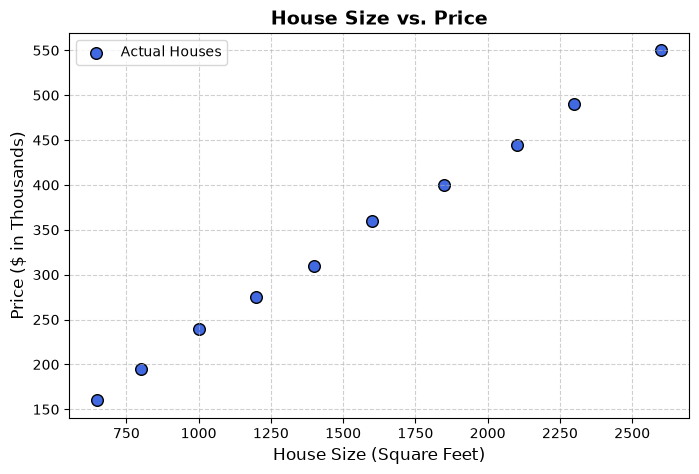

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(sizes, prices, color='royalblue', s=70, edgecolors='black', label='Actual Houses')
plt.title('House Size vs. Price', fontsize=14, fontweight='bold')
plt.xlabel('House Size (Square Feet)', fontsize=12)
plt.ylabel('Price ($ in Thousands)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Step 4: Split into Training and Testing Sets

We split our data so the model learns from 80% of the houses and is tested on the remaining 20%.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(sizes, prices, test_size=0.2, random_state=42)

print(f"Training houses: {len(X_train)}")
print(f"Testing houses:  {len(X_test)}")

Training houses: 8
Testing houses:  2


## Step 5: Train the Linear Regression Model

Training calculates the slope and intercept of the best straight line.

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

print(f"Formula learned by the model: Price = ({slope:.3f} * Size) + {intercept:.2f}\n")
print(f"Everyday explanation:")
print(f" - Each extra 1 sq ft adds about ${slope * 1000:.2f} to the house price.")
print(f" - Base price (intercept): ${intercept:.2f}k (${intercept * 1000:,.0f}).")

Formula learned by the model: Price = (0.197 * Size) + 37.84

Everyday explanation:
 - Each extra 1 sq ft adds about $196.55 to the house price.
 - Base price (intercept): $37.84k ($37,845).


## Step 6: Plot the Best-Fit Line

Let's visualize the straight line our model learned alongside the actual houses.

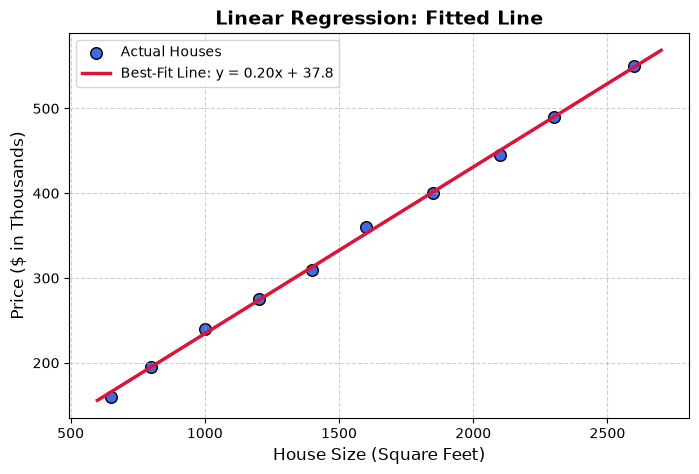

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(sizes, prices, color='royalblue', s=70, edgecolors='black', label='Actual Houses')

# Generate points for drawing the regression line
x_line = np.linspace(600, 2700, 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.plot(x_line, y_line, color='crimson', linewidth=2.5, label=f'Best-Fit Line: y = {slope:.2f}x + {intercept:.1f}')
plt.title('Linear Regression: Fitted Line', fontsize=14, fontweight='bold')
plt.xlabel('House Size (Square Feet)', fontsize=12)
plt.ylabel('Price ($ in Thousands)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Step 7: Predict Price for a New House

Now let's use our trained model to predict the price of a house with **1,750 square feet**.

In [7]:
new_house = np.array([[1750]])
pred_price = model.predict(new_house)[0]

print(f"New House Size: 1,750 sq ft")
print(f"Predicted Price: ${pred_price:.2f}k (${pred_price * 1000:,.0f})")

New House Size: 1,750 sq ft
Predicted Price: $381.81k ($381,810)


## Step 8: Evaluate Model Accuracy

We test how well the model predicts on the test set:
- **R-squared ($R^2$):** A score between 0 and 1 showing how well the line fits the data (1.0 is a perfect score).
- **Mean Squared Error (MSE):** The average squared difference between true prices and predicted prices (lower is better).

In [8]:
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Evaluation on Unseen Test Houses:")
print(f" - R-squared (R2) Score: {r2:.4f} (99%+ of price variation explained!)")
print(f" - Mean Squared Error (MSE): {mse:.2f}")

Evaluation on Unseen Test Houses:
 - R-squared (R2) Score: 1.0000 (99%+ of price variation explained!)
 - Mean Squared Error (MSE): 0.01


## 🎉 Key Takeaways
- **Linear Regression** draws the optimal straight line through numeric data.
- The **slope** tells us the rate of change, and the **intercept** is the starting value.
- We can easily make new predictions with `model.predict()`.